## Setting the basics

The following cells need to be run at the beginning of **each** session. 
They are the relevant variables and paths for all of the following sections. 
All sections are (mostly) independent, only section 1 needs to be run at least once before the other sections are executed, as the other sections depend on the nucleus to patch assignment.

Variables that are unique to the section can be changed at the beggining of each section.

If you want to run different sections for different variables (e.g. section 1 for person CRC_P1 and section 2 for person CRC_P5), please change the respective value in one of the following cells, rerun it and then run the section you desire. 

In [1]:
import os, json, gc
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import scanpy as sc
from shapely.geometry import box, Polygon, Point
from shapely.affinity import translate

In [2]:
# Variables
person = "CRC_P1"
bin_size = "002um"
patch_size = 224

# Set to true if you want to work on a single slide. 
# Set to False if you want to work on all slides 
single_slide = False 

In [3]:
### Paths

## UNI model and patches
uni_metadata_folder = "../uni/notebooks/metadata"
uni_patch_embeddings_filename = "filtered_WSI_patch_embeddings.h5ad"
patch_basepath = os.path.join("../uni/notebooks/patches", person)


## Nuclei
if single_slide:
    cell_seg_folder = f"../Cell_Segmentation/output/{person}/{bin_size}/custom_binning"
    print(f"Set folder: {person} as base folder")
else:
    cell_seg_folder = f"../Cell_Segmentation/output/merged_custom_binning/{bin_size}"
    print("Set merged folder as base folder")

filtered_bins_filename = "filtered_custom_bins.h5ad"

# Reminder: this contains nucleus IDs as obs. These were previously created through custom binning 
#           and now contain summed up embeddings PER NUCLEUS. 
# The corresponding polys are stored in the parquet file. 
nuclei_genes_filtered_filename = "count_area_filtered_adata.h5ad"
nuclei_polys_filename = "nuclei_geometry.parquet"

Set merged folder as base folder


- `adata_patches`: AnnData file containing patch embeddings for each patch, identified by index `SlideID_PatchID`. Also contains both Slide_ID and Patch_ID as separate columns
- `nuclei_positions`: parquet file loaded as a geopandas data frame. Contains the polygons for each nucleus, which are identified by the nucleus ID and the Slide ID, if there is more than one slide.
- `adata_filtered_nuclei`: AnnData File containing embeddings and more for each (filtered) nucleus from each slide. Indexed by Slide_ID and nucleus_ID.


Since we already have geometries for nuclei and positions for patches, we will use spatial joins from GeoPandas.

In [4]:
## Loading the Files

# UNI model
adata_patches = sc.read_h5ad(os.path.join(uni_metadata_folder, uni_patch_embeddings_filename))

# Nuclei
# Nuclei information
nuclei_positions = gpd.read_parquet(os.path.join(cell_seg_folder, nuclei_polys_filename))
adata_filtered_nuclei = sc.read_h5ad(os.path.join(cell_seg_folder, nuclei_genes_filtered_filename))

# merge nuclei positions with adata_filtered_nuclei
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on=["Slide_ID", "id"], how="left")


# 1 Assigning Transcriptomics Info to Patches
In this section we aim to combine transcriptomics and histology by determining which nucleus polygon or bin should be assigned to which patch.
For this we create a polygon for each patch and then load the polygons for each nucleus/bin.
We then determine the overlap.
Currently, we assign each nucleus to exactly one patch by choosing the largest overlapping portion (percent wise). 
Optionally, the user can also decide to return a dataframe containing the overlapping percentages for a nucleus for each patch in Step 3 in the function `assign_cells_to_patches`.

**Assigning Cells to Patches**  
The functions below maps cells to patches. 
- `def assign_cells_to_patches`: This functions takes both the histology and the transcriptomics data to calculate an overlap of the nuclei with the patches from each slide. 
For this, a polygon for each patch is created aand then an overlap is calculated for each nucleus polygon to determine overlap percentage with possible patch polygons. 
We either return a dict that has the structure Slide_ID: {nucleus_ID: assigned patch_ID} or (if overlap percentage is desired) a panads dataframe containing the nucleus ID, the patches with overlay and the calculated overlay percentage per patch. 
- `def get_patch_for_cell`: Takes the required Slide_ID and Nucleus_ID from the `adata_filtered_nuclei` and returns the assigned patch from the dictionary. 
This information is later added to the `adata_filtered_nuclei.obs` in a new column called `Patch_ID`.
The AnnData object is then stored in a new file called `patch_assigned_count_area_filtered_adata.h5ad`, in the same folder as the original anndata object. 


In [ ]:
# Functions for assining cells to patches and adding the Patch IDs back to the adata_filtered_nuclei.
# Function to assign cells to patches based on maximum overlap. Per individual slide/person. 
# hist_data: Histology AnnData (see uni model). ID: slideID_patchID, patches with embeddings, contain Slide_ID (i.e. person) and top left pixel corner (X, Y)
# trans_data = Transcriptomics. ID: nucleus_ID ("ID"), contains (among others) geometry (polygon of nucleus in pixels)
# slide_id = person
# box_size = set to patch_size
def assign_cells_to_patches(hist_data, trans_data, slide_id, box_size=224, sample=None):

    print(f"Working on single slide: {slide_id}")
    core_data_hist = hist_data[hist_data['Slide_ID'] == slide_id]
    if core_data_hist.empty:
        print(f"No box data for {slide_id}")
        return {}


    patch_geometries = [
        box(row['X'], row['Y'], row['X'] + box_size, row['Y'] + box_size)
        for _, row in core_data_hist.iterrows()
    ]
    patches_gdf = gpd.GeoDataFrame(core_data_hist[['Patch_ID']], geometry=patch_geometries, crs=None)
    patches_gdf['patch_index'] = patches_gdf.index  # in case match_id is not unique

    # turn trans_data into gdf for polygon operations
    trans_data = trans_data[trans_data.obs["Slide_ID"] == slide_id] 
    
    transcr_gdf = gpd.GeoDataFrame(
        trans_data.obs.reset_index(drop=True), 
        geometry=trans_data.obs.reset_index(drop=True)["geometry"],
        crs=None
    )

    print(f"Transcriptomics bounds for {person}:", transcr_gdf.total_bounds)  # minx, miny, maxx, maxy of nuclei
    print(f"Histology bounds for {person}:", patches_gdf.total_bounds)

    overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')
 
    overlaps['intersection_area'] = overlaps.geometry.area
    overlaps['cell_area'] = overlaps.groupby('id')['intersection_area'].transform('sum')

    overlaps['percent_covered'] = overlaps['intersection_area'] / overlaps['cell_area']


    best_matches = overlaps.sort_values('percent_covered', ascending=False).drop_duplicates(subset='id')

    # best_matches['id']=sample + "_" + best_matches['id'].astype(str)
    best_matches['id']=best_matches['id'].astype(str)
    
    # check unique matches
    n_unique = best_matches["id"].unique()
    n_non_unique = best_matches["id"].count() - len(n_unique)
    if n_non_unique > 0:
        print(f"Warning: {n_non_unique} nuclei have been assigned to multiple patches for {slide_id}.")
    
    cell_to_patch = dict(zip(best_matches['id'], best_matches['Patch_ID']))

    # return pd.DataFrame(best_matches[['id', 'Patch_ID', 'percent_covered']])
    return cell_to_patch # or pd.DataFrame(best_matches[['index', 'match_id', 'percent_covered']])



def get_patch_for_cell(row, all_mappings):
    slide = row["Slide_ID"]
    nucleus_id = row["id"]
    return all_mappings.get(slide, {}).get(nucleus_id, None)


In [ ]:
all_mappings = {}

people = adata_filtered_nuclei.obs["Slide_ID"].unique() 
check_people = adata_patches.obs["Slide_ID"].unique() 

print("People in nuclei file: ", people)
print("People in patches: ", check_people)

for person in people:
    print(f"Processing {person}...")
    if person not in check_people:
        print(f"Skipping {person} as no patches are available.")
        continue

    mapping = assign_cells_to_patches(adata_patches.obs, adata_filtered_nuclei, person, 224, person)
    all_mappings[person] = mapping

#if not single_slide:
adata_filtered_nuclei.obs["Patch_ID"] = adata_filtered_nuclei.obs.apply(
    get_patch_for_cell, axis=1, args=(all_mappings,)
)
#else:
    #adata_filtered_nuclei.obs["Patch_ID"] = adata_filtered_nuclei.obs["id"].map(mapping)

In [ ]:
# Drop geometry again
# Save to new Anndata file (for now)
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.drop(columns=["geometry"])
adata_filtered_nuclei.write(os.path.join(cell_seg_folder, "patch_assigned_count_area_filtered_adata.h5ad"))

# 2. Stitching together all filtered patches of one image  

The code below takes one slide (change variable `person` to desired image) and the filtered AnnData object, that should contain this slide's information. 
We then plot all patches AFTER filtering (meaning after filtering out patches with no tissue) to one canvas.

In [7]:
## Function to load and plot all patches given in the adata object
# adata: the Anndata object that contains paths to patches, patch coordinates and more. 
# Typically: "filtered_WSI_patch_embeddings.h5ad" or a filtered version
def plot_image_from_patches(adata_patches, patch_size, patch_basepath, person):
    x_coords = adata_patches.obs["X"].values
    y_coords = adata_patches.obs["Y"].values
    patch_ids = adata_patches.obs["Patch_ID"].values

    # Compute axis limits
    min_x, max_x = x_coords.min(), x_coords.max() + patch_size
    min_y, max_y = y_coords.min(), y_coords.max() + patch_size

    fig, ax = plt.subplots(figsize=(12, 12))

    patch_count = adata_patches.obs["Patch_ID"].nunique()
    print(f"Plotting tissue image of person {person} using {patch_count} patches...")

    for x, y, patch_id in zip(x_coords, y_coords, patch_ids):
        patch_path = os.path.join(patch_basepath, patch_id)
        img = Image.open(patch_path).convert("RGB")

        # Place patch at correct coordinates
        ax.imshow(img, extent=[x, x+patch_size, y+patch_size, y])


    # Invert Y-axis for correct image orientation
    ax.invert_yaxis()
    ax.axis("off")

    # Set axis limits
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)

    plt.show()

Plotting tissue image of person CRC_P1 using 9119 patches...


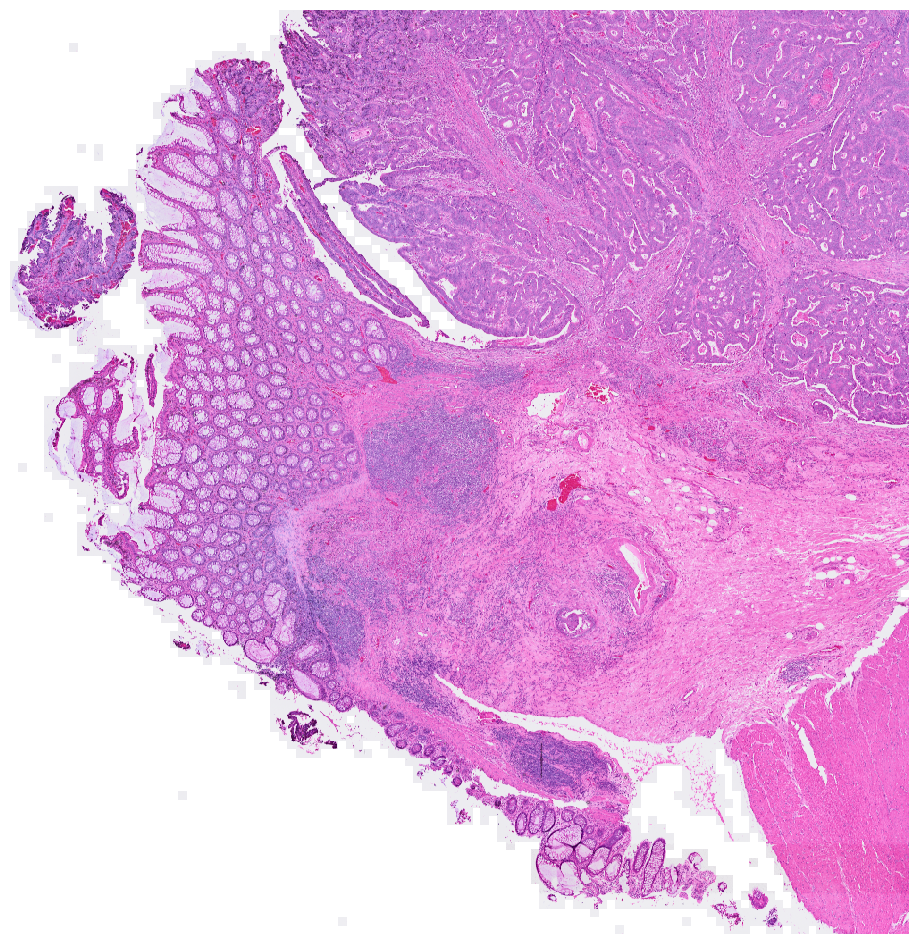

In [8]:
# Filter for ONE slide
mask = adata_patches.obs["Slide_ID"] == person
adata_filtered = adata_patches[mask]

plot_image_from_patches(adata_filtered, patch_size, patch_basepath, person)

## 3. Plotting one patch with its assigned nuclei 

This code plots one selected image patch and the nuclei that were discovered by StarDist over the patch. 
You can select the patch by setting both the variables `patch_id` for the specific patch and `person` for the slide the patch comes from.  

Then we follow these steps:
1. Load patch image and pixel offset
2. Get nuclei and nuclei polygons for the patch
3. Overlay plot

**Note**: These functions currently only assume three possible bin sizes: 2um, 8um and 16um. 

In [5]:
# Load the AnnData object from section 1. of this notebook, containing a patch assignment for each nucleus
adata_filtered_nuclei_with_patch = sc.read_h5ad(os.path.join(cell_seg_folder, "patch_assigned_count_area_filtered_adata.h5ad"))
if single_slide:
    print("WARNING: You are currently working from a single slide folder, not the merged folder for all slides.")

# Merge Nuclei IDs with their respective polygons
adata_filtered_nuclei_with_patch.obs = adata_filtered_nuclei_with_patch.obs.merge(nuclei_positions, on=["Slide_ID", "id"], how="left")

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [11]:
bins = sc.read_h5ad(os.path.join(cell_seg_folder, "filtered_custom_bins.h5ad"))
bins_df = bins.obs

 # select bins belonging to this patch
bins_patch = bins_df.query("Slide_ID == @person")

In [11]:
import matplotlib.patches as patches
from shapely.geometry import Point, box


# --------------------------------------------------------------------------
# Helper: Load bin size (in full-res pixels)
# --------------------------------------------------------------------------
def load_scalefactors(person, bin_size):
    """
    Loads 'spot_diameter_fullres' from scalefactors_json.json.
    For Visium HD, this corresponds to the side length of a 2 µm bin in full-resolution pixels.
    """
    scale_path = f"../data/{person}/output/binned_outputs/square_{bin_size}/spatial/scalefactors_json.json"
    with open(scale_path, "r") as f:
        scales = json.load(f)

    # In full-resolution BTF coordinates, this is the correct field.
    spot_px = scales["spot_diameter_fullres"]
    return spot_px


# --------------------------------------------------------------------------
# Main: Plot patch + nuclei + bins inside nuclei
# --------------------------------------------------------------------------
def plot_patch_with_nuclei(
    patch_id,
    patch_basepath,
    uni_metadata_folder,
    person,
    nuclei_w_patches,
    bin_size,
    cell_seg_folder,
):
    """
    Plots a patch (from the original full-resolution BTF) with:
      - nuclei outlines (black)
      - bins that fall inside nuclei (red squares)
    Returns:
      gdf_nuclei_shifted, gdf_bins_in_nuclei, offset_x, offset_y
    """

    # --- 1. Bin size in µm for reference ---
    bin_size_um = {"002um": 2.0, "008um": 8.0, "016um": 16.0}[bin_size]

    # --- 2. Load patch image (from full-res BTF) ---
    patch_img = Image.open(f"{patch_basepath}/{patch_id}")

    # --- 3. Load patch metadata (global offsets) ---
    positions = pd.read_csv(os.path.join(uni_metadata_folder, "WSI_patch_metadata.csv"))
    positions = positions.set_index(["Slide_ID", "Patch_ID"])
    offset_x, offset_y = positions.loc[(person, patch_id), ["X", "Y"]]

    # --- 4. Load scalefactors: bin side length in pixels ---
    bin_side_px = load_scalefactors(person, bin_size)


    # --- 7. Get nuclei for this patch ---
    nuclei = nuclei_w_patches.obs.query("Patch_ID == @patch_id and Slide_ID == @person")
    gdf_nuclei = gpd.GeoDataFrame(nuclei, geometry="geometry")

    # shift nuclei polygons into patch coordinate system
    gdf_nuclei_shifted = gdf_nuclei.copy()
    gdf_nuclei_shifted["geometry"] = gdf_nuclei_shifted["geometry"].translate(
        xoff=-offset_x, yoff=-offset_y
    )

    # --- 5. Load bins ---
    bins = sc.read_h5ad(os.path.join(cell_seg_folder, "filtered_custom_bins.h5ad"))
    bins_df = bins.obs

    # select bins belonging to this patch
    bins_patch = bins_df.query("Slide_ID == @person")
    nucleus_ids = nuclei["id"].tolist()
    bins_patch = bins_patch[bins_patch["id"].isin(nucleus_ids)]
    print(f"Found {bins_patch.shape[0]} bins for patch {patch_id}.")

    # shift bin positions into patch coordinates
    bins_patch["x_patch"] = bins_patch["pxl_col_in_fullres"] - offset_x
    bins_patch["y_patch"] = bins_patch["pxl_row_in_fullres"] - offset_y

    # --- 6. Represent bins as SQUARES (not circles) ---
    half_side = bin_side_px / 2.0
    bins_patch["geometry"] = bins_patch.apply(
        lambda r: box(
            r["x_patch"] - half_side,
            r["y_patch"] - half_side,
            r["x_patch"] + half_side,
            r["y_patch"] + half_side,
        ),
        axis=1,
    )
    # gdf_bins = gpd.GeoDataFrame(bins_patch, geometry="geometry", crs="pixel")
    gdf_bins = gpd.GeoDataFrame(bins_patch, geometry="geometry")


    # --- 8. Spatial join: which bins fall inside which nuclei ---
    gdf_bins_in_nuclei = gpd.sjoin(gdf_bins, gdf_nuclei_shifted, predicate="within", how="inner")

    # --- 9. Plotting ---
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(patch_img)

    # nuclei outlines
    gdf_nuclei_shifted.boundary.plot(ax=ax, edgecolor="black", linewidth=1, alpha=0.7)

    # bins inside nuclei (red squares)
    for geom in gdf_bins_in_nuclei.geometry:
        x, y, w, h = geom.bounds
        ax.add_patch(
            patches.Rectangle(
                (x, y),
                w - x,
                h - y,
                linewidth=0.3,
                edgecolor="black",
                facecolor="none",
                alpha=0.7,
            )
        )

    plt.title(f"Patch {patch_id}\nNuclei (black) + bins inside nuclei (red)")
    plt.axis("off")
    plt.show()

    # --- 10. Cleanup ---
    del positions, bins
    gc.collect()

    return gdf_nuclei_shifted, gdf_bins_in_nuclei, offset_x, offset_y


In [7]:
# Function that prints statistics and information on the selected patch and the contained nuclei.
# Returns: dict with patch info
def print_stats(patch_id, person, nuclei, offset_x, offset_y, bin_size):
   # Load JSON scalefactors to convert from pixel to real size
   bin_size_in_pxl = get_bin_size(person, bin_size)

   ## Print Patch Information
   print("##### Patch information #####")
   print("Person: ", person)
   print("Patch ID: ", patch_id)
   print(f"Top left pixel coordinate of the slide: {offset_x}, {offset_y}")
   print(f"Nuclei found for person {person} in {patch_id}: {nuclei.shape[0]}.") 

   patch_dict = {
      "Slide_ID": person,
      "Patch_ID": patch_id,
      "top_pxl_x": offset_x,
      "top_pxl_y": offset_y,
      "nuclei_count": nuclei.shape[0],
      "nuclei": {}
   }

   # Print nuclei information
   bins = sc.read_h5ad(os.path.join(cell_seg_folder, "filtered_custom_bins.h5ad"))
   
   print("##### Nuclei Information #####")
   print(f"Scalefactor (µm/pixel): {bin_size_in_pxl}")
   print(f"Pixels per µm: {1 / bin_size_in_pxl}")
   patch_dict["scalefactor"] = bin_size_in_pxl
   patch_dict["scalefactor_pxl_per_um"] = 1/bin_size_in_pxl

   for nucleus in nuclei.itertuples(index=False):
      nucleus_id = nucleus.id
      filtered_bins = bins.obs.query("Slide_ID == @person and id == @nucleus_id")
      bin_count = filtered_bins.shape[0]
      area = nucleus.geometry.area
      area_converted = area * (bin_size_in_pxl ** 2)
      
      print(f" -------------- Nucleus {nucleus_id} --------------")
      print(f"Bin count: {bin_count} bins")
      print(f"Area: {area:.2f} pixels² and {area_converted:.2f} um².")

      patch_dict["nuclei"][nucleus_id] = {
        "bin_count": bin_count,
        "area_px": area,
        "area_um": area_converted
      }

   # Free RAM
   del bins
   gc.collect()

   return patch_dict

Found 59 bins for patch patch_7053.png.


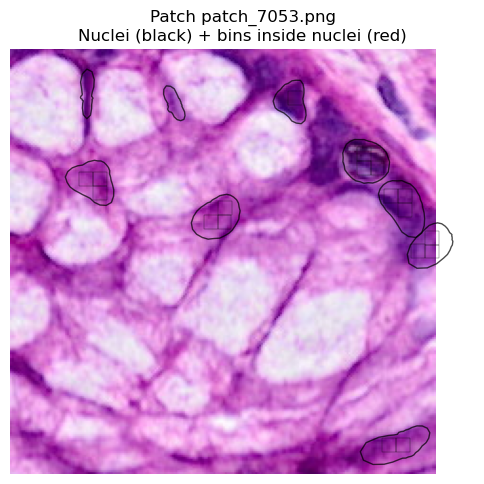

Unique Patch_IDs: 6422


In [ ]:
# choose patch
patch_id = "patch_7053.png"  # example

# Plot one patch and its assigned nuclei
gdf_nuclei_shifted, gdf_bins_in_nuclei, offset_x, offset_y = plot_patch_with_nuclei(
    patch_id, 
    patch_basepath, 
    uni_metadata_folder, 
    person, 
    adata_filtered_nuclei_with_patch, 
    bin_size, cell_seg_folder)

# Print statistics for the patch and nuclei
patch_stats_dict = print_stats(patch_id, person, gdf_nuclei_shifted, offset_x, offset_y, bin_size)

adata_single_person = adata_filtered_nuclei_with_patch.obs.query("Slide_ID == @person")
n_unique = adata_single_person["Patch_ID"].nunique()
print("Unique Patch_IDs:", n_unique)

# 4. Plotting only patches that contain nuclei
**Note:** If you haven't tun the previous sections before this section during this kernel session, please run the second cell (plotting function) from section 2. before running the cells following below.

In [12]:
# Nuclei information
adata_filtered_nuclei_with_patch = sc.read_h5ad(os.path.join(cell_seg_folder, "patch_assigned_count_area_filtered_adata.h5ad"))
adata_filtered_nuclei_with_patch.obs = adata_filtered_nuclei_with_patch.obs.merge(nuclei_positions, on=["Slide_ID", "id"], how="left")

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [13]:
# Filter patches for ONE slide
mask = adata_patches.obs["Slide_ID"] == person
adata_filtered_patches = adata_patches[mask]

In [14]:
# Filtering nuclei AnnData object for single person
print(f"Currently working on {person}...")
adata_nuclei_single_person = adata_filtered_nuclei_with_patch.obs.query("Slide_ID == @person")
patch_count = adata_filtered_patches.obs["Patch_ID"].nunique()
print(f"Patch count BEFORE filtering for only patches that overlap with at least one nucleus: {patch_count}")

# Filtering out patches with no assigned nucleus
patches_with_nuclei = adata_nuclei_single_person["Patch_ID"].unique()
adata_filtered_patches = adata_filtered_patches[adata_filtered_patches.obs["Patch_ID"].isin(patches_with_nuclei)]
patch_count = adata_filtered_patches.obs["Patch_ID"].nunique()
print(f"Patch count AFTER filtering for only patches that overlap with at least one nucleus: {patch_count}")


Currently working on CRC_P1...
Patch count BEFORE filtering for only patches that overlap with at least one nucleus: 9119
Patch count AFTER filtering for only patches that overlap with at least one nucleus: 6422


Plotting tissue image of person CRC_P1 using 6422 patches...


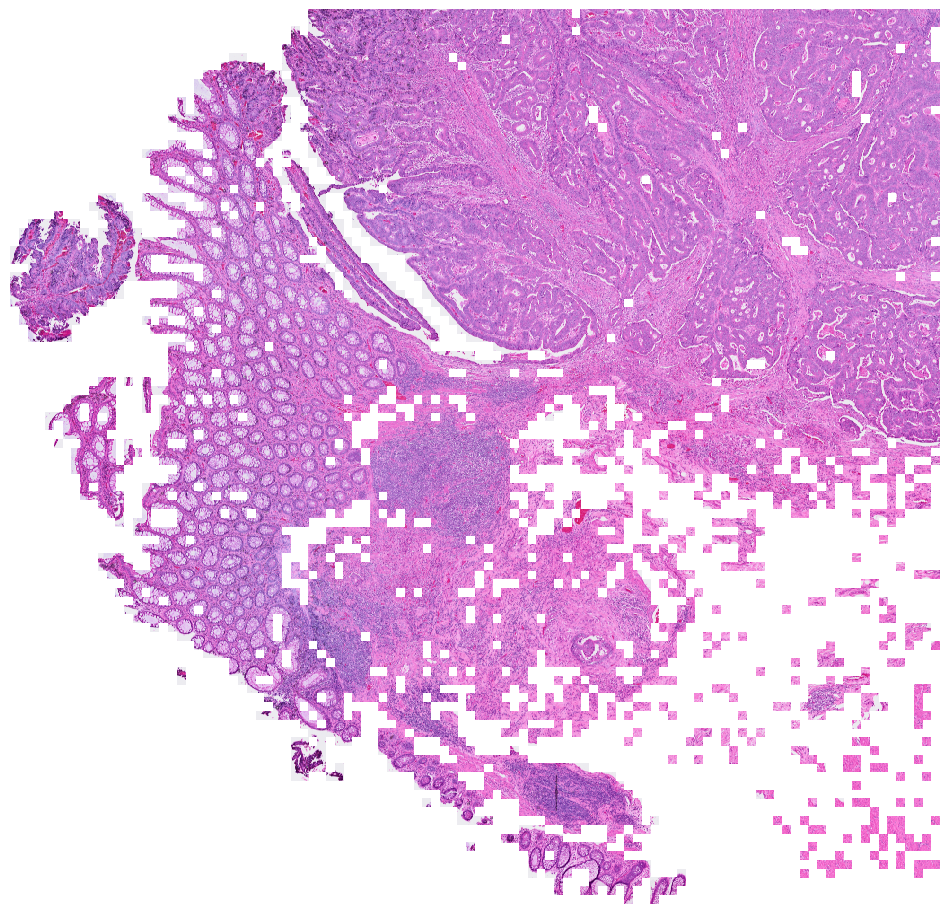

In [14]:
# Plotting the image
plot_image_from_patches(adata_filtered_patches, patch_size, patch_basepath, person)